<a href="https://colab.research.google.com/github/snigdhareddy-20/-DEEP_LEARNING/blob/main/DL_S7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Tue Nov 24 03:36:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Enable GPU in Runtime settings.")

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU: Tesla T4


In [3]:
!pip install -q ultralytics onnx onnxruntime

In [4]:
import os
import torch
import onnx
import onnxruntime as ort

from ultralytics import YOLO

print("All libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!


In [5]:
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


In [6]:
model.info()

YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

In [7]:
print(model.model)

DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
  

In [8]:
checkpoint_path = "yolov8n.pt"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Checkpoint size:",
      round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2),
      "MB")

Checkpoint exists: True
Checkpoint size: 6.25 MB


In [9]:
import shutil

shutil.copy(
    checkpoint_path,
    "/content/yolov8n_checkpoint.pt"
)

print("Checkpoint saved successfully!")

Checkpoint saved successfully!


In [10]:
from ultralytics.utils import ASSETS

image_path = str(ASSETS / "bus.jpg")

results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("Original checkpoint inference completed!")


image 1/1 /usr/local/lib/python3.13/dist-packages/ultralytics/assets/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 9.4ms
Speed: 79.6ms preprocess, 9.4ms inference, 37.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
Original checkpoint inference completed!


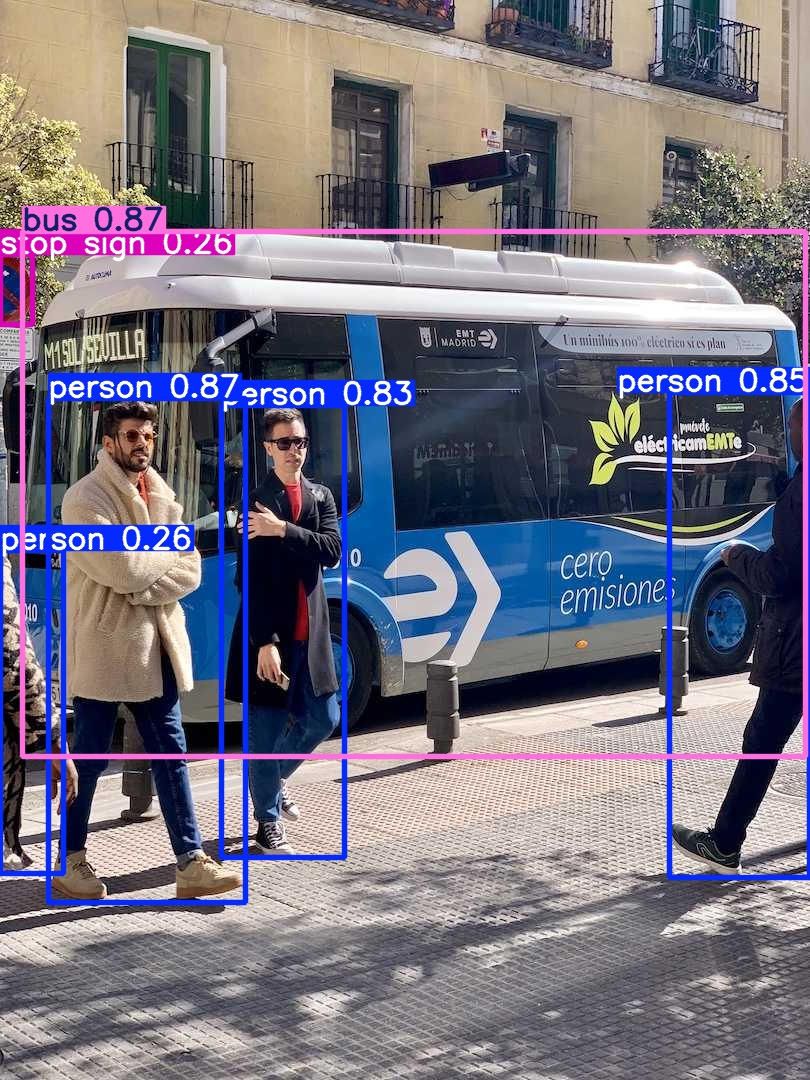

In [11]:
from IPython.display import display, Image

display(Image(filename="runs/detect/predict/bus.jpg"))

In [12]:
onnx_path = model.export(
    format="onnx",
    imgsz=640,
    opset=12,
    simplify=True
)

print("ONNX export completed!")
print("ONNX file:", onnx_path)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from 'yolov8n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 328ms
Prepared 2 packages in 72ms
Installed 2 packages in 10ms
 + colorama==0.4.6
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.2s, saved as 'yolov8n.onnx' (12.3 MB)

Export complete (2.6s)
Res

In [13]:
onnx_model = onnx.load(str(onnx_path))

onnx.checker.check_model(onnx_model)

print("ONNX model is valid!")

ONNX model is valid!


In [14]:
print("ONNX Graph Information")
print("----------------------")

print("Number of nodes:", len(onnx_model.graph.node))

print("\nModel Inputs:")
for input_tensor in onnx_model.graph.input:
    print(input_tensor.name)

print("\nModel Outputs:")
for output_tensor in onnx_model.graph.output:
    print(output_tensor.name)

ONNX Graph Information
----------------------
Number of nodes: 234

Model Inputs:
images

Model Outputs:
output0


In [15]:
onnx_session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"]
)

print("ONNX Runtime session created!")

ONNX Runtime session created!


In [16]:
for input_info in onnx_session.get_inputs():
    print("Input name:", input_info.name)
    print("Input shape:", input_info.shape)
    print("Input type:", input_info.type)

Input name: images
Input shape: [1, 3, 640, 640]
Input type: tensor(float)


In [17]:
onnx_model_yolo = YOLO(str(onnx_path))

onnx_results = onnx_model_yolo.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("ONNX inference completed!")

Loading yolov8n.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime-gpu[cuda]'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 554ms
Prepared 1 package in 4.35s
Installed 1 package in 21ms
 + onnxruntime-gpu==1.32.0

requirements: AutoUpdate success ✅ 5.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.32.0 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...

image 1/1 /usr/local/lib/python3.13/dist-packages/ultralytics/assets/bus.jpg: 640x640 4 persons, 1 bus, 127.8ms
Speed: 5.6ms preprocess, 127.8ms inference, 13.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-2
ONNX inference completed!


In [18]:
try:
    import tensorrt as trt

    print("TensorRT Version:", trt.__version__)

except ImportError:
    print("TensorRT is not installed.")

TensorRT is not installed.


In [19]:
import tensorrt as trt

print("TensorRT Version:", trt.__version__)

ModuleNotFoundError: No module named 'tensorrt'

In [20]:
!nvidia-smi

Tue Nov 24 03:44:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   68C    P0             31W /   70W |     165MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [21]:
!python -m pip install --upgrade tensorrt-cu13

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... canceledERROR: Operation cancelled by user
^C


In [1]:
!python -m pip install --upgrade tensorrt-cu13

  Using cached tensorrt_cu13-11.5.0.63.tar.gz (17 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached tensorrt_cu13_libs-11.5.0.63.tar.gz (15 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 17.8 MB/s  0:00:00
  Created wheel for tensorrt-cu13: filename=tensorrt_cu13-11.5.0.63-py3-none-any.whl size=23057 sha256=b9d901bcbe4bfb930785b0e8098218587d2197b223acacd0158fdabe11b37cee
  Stored in directory: /root/.cache/pip/wheels/89/4d/e8/f493972a5dc2a1733d7b9f43abd67b965e2356ac4c8657e0fc
  Created wheel for tensorrt_cu13_libs: filename=tensorrt_cu13_libs-11.5.0.63-py3-none-manylinux_2_28_x86_64.whl size=3836415489 sha256=56f4b6764cf86ed22202234b7a89d22a6b817493ab76f0c9d1a8d55d8497efdc
  Stored in directory: /root/.cache/pip/wheels/5e/a8/60/f4680682020

In [1]:
import tensorrt as trt

print("TensorRT Version:", trt.__version__)

logger = trt.Logger()
builder = trt.Builder(logger)

print("TensorRT Builder created:", builder is not None)

TensorRT Version: 11.5.0.63
TensorRT Builder created: True


In [2]:
import ultralytics
from ultralytics import YOLO
import torch

print("Ultralytics Version:", ultralytics.__version__)
print("CUDA Available:", torch.cuda.is_available())

model = YOLO("yolov8n.pt")
print("YOLOv8 model loaded successfully!")

Ultralytics Version: 8.4.218
CUDA Available: True
YOLOv8 model loaded successfully!


In [3]:
engine_path = model.export(
    format="engine",
    imgsz=640,
    quantize=16,
    device=0
)

print("TensorRT Engine:", engine_path)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from 'yolov8n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.2s, saved as 'yolov8n.onnx' (12.3 MB)

TensorRT: starting export with TensorRT 11.5.0.63...
requirements: Ultralytics requirement ['nvidia-modelopt[onnx]>=0.44'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 66 packages in 2.13s
Prepared 14 packages in 24.68s
Uninstalled 3 packages in 124ms
Installed 14 packages in 431ms
 + cppimport==26.4.17
 + lief==1.0.0
 + mako==1.4.3
 + ninja==1.13.2
 + nvidia-modelopt==0.48.0
 - onnx==1.23.2
 + onnx==1.21.0
 + onnx-graphsurgeon==0.6.1
 + onnx-ir==1.1.0
 + onnxconverter-common==1.16.0
 - onnxruntime-gpu==1.32.0
 +

2026-11-24 03:50:22,870 - [modelopt][onnx] - INFO - Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']


INFO:modelopt.onnx:Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']


2026-11-24 03:50:23,372 - [modelopt][onnx] - INFO - Running ONNX Runtime to obtain reference outputs (this may take a while)...


INFO:modelopt.onnx.autocast:Running ONNX Runtime to obtain reference outputs (this may take a while)...


2026-11-24 03:50:24,206 - [modelopt][onnx] - WARNING - Did not find  in value info map! Assuming not castable


2026-11-24 03:50:25,114 - [modelopt][onnx] - INFO - Converted 233/233 nodes (100.00%) to fp16


INFO:modelopt.onnx.autocast:Converted 233/233 nodes (100.00%) to fp16


TensorRT: input "images" with shape(1, 3, 640, 640) DataType.FLOAT
TensorRT: output "output0" with shape(1, 84, 8400) DataType.FLOAT
TensorRT: building FP16 engine as yolov8n.engine
TensorRT: export success ✅ 179.4s, saved as 'yolov8n.engine' (62.1 MB)

Export complete (181.9s)
Results saved to /content/yolov8n.engine
Predict:         yolo predict task=detect model=yolov8n.engine imgsz=640 quantize=16
Validate:        yolo val task=detect model=yolov8n.engine imgsz=640 data=coco.yaml quantize=16
Visualize:       https://netron.app
TensorRT Engine: yolov8n.engine


In [4]:
import os

print("Engine exists:", os.path.exists(str(engine_path)))

Engine exists: True


In [5]:
from ultralytics import YOLO

# Load TensorRT engine
engine_model = YOLO(str(engine_path), task="detect")

# Perform inference
engine_results = engine_model.predict(
    source=image_path,
    conf=0.25,
    save=True,
    device=0
)

print("TensorRT inference completed successfully!")

NameError: name 'image_path' is not defined

In [6]:
from ultralytics.utils import ASSETS

image_path = str(ASSETS / "bus.jpg")

print("Test image:", image_path)
print("Image exists:", os.path.exists(image_path))

Test image: /usr/local/lib/python3.13/dist-packages/ultralytics/assets/bus.jpg
Image exists: True


In [7]:
from ultralytics import YOLO

engine_model = YOLO(str(engine_path), task="detect")

engine_results = engine_model.predict(
    source=image_path,
    conf=0.25,
    save=True,
    device=0
)

print("TensorRT inference completed successfully!")

Loading yolov8n.engine for TensorRT inference...

image 1/1 /usr/local/lib/python3.13/dist-packages/ultralytics/assets/bus.jpg: 640x640 4 persons, 1 bus, 3.4ms
Speed: 22.7ms preprocess, 3.4ms inference, 22.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-3
TensorRT inference completed successfully!


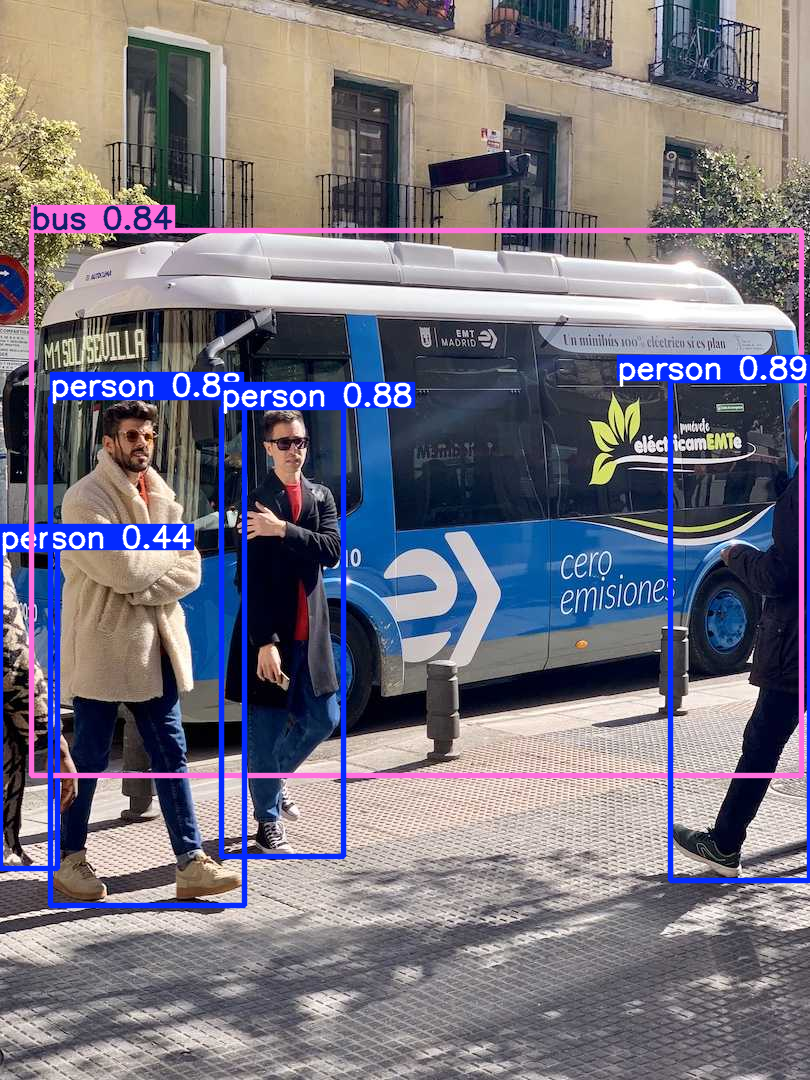

In [8]:
from google.colab.patches import cv2_imshow

annotated_image = engine_results[0].plot()

cv2_imshow(annotated_image)

In [9]:
import os

artifacts = [
    "yolov8n.pt",
    "yolov8n_checkpoint.pt",
    "yolov8n.onnx",
    str(engine_path)
]

print("FINAL MODEL ARTEFACT REPORT")
print("=" * 40)

for artifact in artifacts:
    if os.path.exists(artifact):
        size = os.path.getsize(artifact) / (1024 * 1024)
        print(f"{artifact}: {size:.2f} MB")
    else:
        print(f"{artifact}: Not found")

FINAL MODEL ARTEFACT REPORT
yolov8n.pt: 6.25 MB
yolov8n_checkpoint.pt: 6.25 MB
yolov8n.onnx: 12.26 MB
yolov8n.engine: 62.12 MB


In [10]:
import time
import numpy as np
from ultralytics import YOLO

pytorch_model = YOLO("yolov8n.pt")
onnx_model = YOLO("yolov8n.onnx")
tensorrt_model = YOLO("yolov8n.engine")

print("All three models loaded successfully!")

All three models loaded successfully!


In [2]:
def measure_inference(model, image_path, runs=20):

    # Warm-up
    for _ in range(5):
        model.predict(
            source=image_path,
            imgsz=640,
            conf=0.25,
            verbose=False
        )

    times = []

    for _ in range(runs):
        start = time.perf_counter()

        model.predict(
            source=image_path,
            imgsz=640,
            conf=0.25,
            verbose=False
        )

        end = time.perf_counter()
        times.append((end - start) * 1000)

    return np.mean(times)


pytorch_time = measure_inference(pytorch_model, image_path)
onnx_time = measure_inference(onnx_model, image_path)
tensorrt_time = measure_inference(tensorrt_model, image_path)

print("PyTorch Average:", round(pytorch_time, 2), "ms")
print("ONNX Average:", round(onnx_time, 2), "ms")
print("TensorRT Average:", round(tensorrt_time, 2), "ms")

NameError: name 'pytorch_model' is not defined

In [3]:
from ultralytics import YOLO

# Load the three model formats
pytorch_model = YOLO("yolov8n.pt")
onnx_model = YOLO("yolov8n.onnx")
tensorrt_model = YOLO("yolov8n.engine")

print("All three models loaded successfully!")

All three models loaded successfully!


In [4]:
from ultralytics.utils import ASSETS

image_path = str(ASSETS / "bus.jpg")

print("Image path:", image_path)

Image path: /usr/local/lib/python3.13/dist-packages/ultralytics/assets/bus.jpg


In [5]:
pytorch_time = measure_inference(pytorch_model, image_path)
onnx_time = measure_inference(onnx_model, image_path)
tensorrt_time = measure_inference(tensorrt_model, image_path)

print("PyTorch:", round(pytorch_time, 2), "ms")
print("ONNX:", round(onnx_time, 2), "ms")
print("TensorRT:", round(tensorrt_time, 2), "ms")

NameError: name 'time' is not defined

In [6]:
import time
import numpy as np
import torch

print("Required modules imported successfully!")

Required modules imported successfully!


In [7]:
def measure_inference(model, image_path, runs=20):

    # Warm-up runs
    for _ in range(5):
        model.predict(
            source=image_path,
            imgsz=640,
            conf=0.25,
            verbose=False
        )

    times = []

    # Actual measurements
    for _ in range(runs):

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        model.predict(
            source=image_path,
            imgsz=640,
            conf=0.25,
            verbose=False
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end = time.perf_counter()

        times.append((end - start) * 1000)

    return np.mean(times)

In [8]:
pytorch_time = measure_inference(pytorch_model, image_path)
onnx_time = measure_inference(onnx_model, image_path)
tensorrt_time = measure_inference(tensorrt_model, image_path)

print("PyTorch:", round(pytorch_time, 2), "ms")
print("ONNX:", round(onnx_time, 2), "ms")
print("TensorRT:", round(tensorrt_time, 2), "ms")

Loading yolov8n.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.30.0 with CUDAExecutionProvider
Loading yolov8n.engine for TensorRT inference...
PyTorch: 19.35 ms
ONNX: 15.84 ms
TensorRT: 10.15 ms
